<h1> Preprocessing <h1/>

<h3> Import Libraries <h3/>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

<h3> Load Dataset<h3/>

In [2]:
df=pd.read_csv(r"../DATA/covertype/covtype.csv")

<h3>Separate features and target<h3/>

In [3]:
x=df.drop('Cover_Type',axis=1)
y=df['Cover_Type']

<h3> Split Data to 3 Parts (Train,Evalidation,Final Test)<h3/>

In [4]:
from sklearn.model_selection import train_test_split
x_train,x_other,y_train,y_other=train_test_split(x,y,train_size=0.7,stratify=y,random_state=101)
x_eval,x_test,y_eval,y_test=train_test_split(x_other,y_other,test_size=0.5,stratify=y_other,random_state=101)

<h3>Feature Scaling<h3/>

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_eval_scaled=scaler.transform(x_eval)


(87152, 54)

<h2> Use PCA to Decomposition<h2/>

<h3>Selecting the Number of PCA Components<h3/>

<h5>The Elbow Method was used to determine a suitable number of principal components. The cumulative explained variance was calculated for different numbers of components and visualized to identify the point where adding more components provides relatively little additional variance.<h5/>

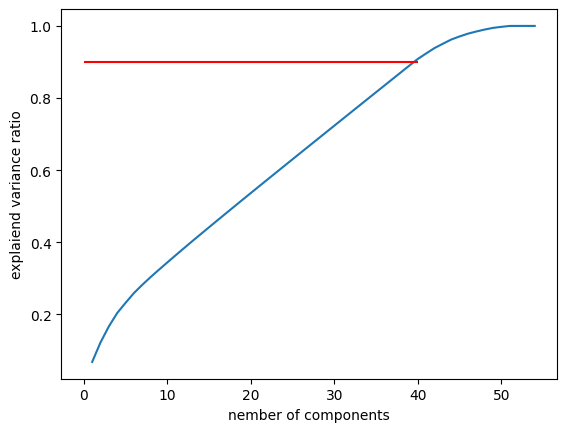

In [8]:
from sklearn.decomposition import PCA
len(x.columns)
var_explain_ratio=[]
for i in range(1,55):
    test=PCA(n_components=i)
    test.fit(x_train_scaled)
    var_explain_ratio.append(np.sum(test.explained_variance_ratio_))
plt.plot(range(1,55),var_explain_ratio)
plt.ylabel('explaiend variance ratio')
plt.xlabel('nember of components')
plt.hlines(y=0.9,xmin=0,xmax=40,colors='red')

Based on the Elbow Method results, reducing the original 54 features to 40 principal components preserves around 90% of the total variance. Therefore, 40 components can be considered a reasonable choice for reducing the dimensionality while retaining most of the information in the dataset.


In [10]:
pca_main_model=PCA(n_components=40)
decomposited_data=pd.DataFrame(pca_main_model.fit_transform(x_train_scaled),columns=range(1,41))

<h3>Save Models And Data<h3/>

In [11]:
import joblib
joblib.dump(pca_main_model,r'../DATA/covertype/pca_model.pkl')
joblib.dump(scaler,r'../DATA/covertype/scaler.pkl')
x.to_csv(r'../DATA/covertype/x.csv',index=False)
y.to_csv(r'../DATA/covertype/y.csv',index=False)
pd.DataFrame(x_train_scaled).to_csv(r'../DATA/covertype/x_train_scaled.csv',index=False)
pd.DataFrame(x_eval_scaled).to_csv(r'../DATA/covertype/x_eval_scaled.csv',index=False)
pd.DataFrame(x_test).to_csv(r'../DATA/covertype/x_test.csv',index=False)
pd.DataFrame(y_train).to_csv(r'../DATA/covertype/y_train.csv',index=False)
pd.DataFrame(y_eval).to_csv(r'../DATA/covertype/y_eval.csv',index=False)
pd.DataFrame(y_test).to_csv(r'../DATA/covertype/y_test.csv',index=False)
decomposited_data.to_csv(r'../DATA/covertype/decomposited_Train_data.csv',index=False)